# O3 with per-update 88-input Lasso and a 96-arrival health bank

**Complete** · seed 2026 · 80,000/80,000 arrivals · ETA 0h 00m 00s

Online wall time 0h 43m 29s. Skip / 0.25× / 1× actions [5508, 11424, 55068]. Updated 2026-11-11T16:05:17+01:00.

## Training, prediction error and compute time

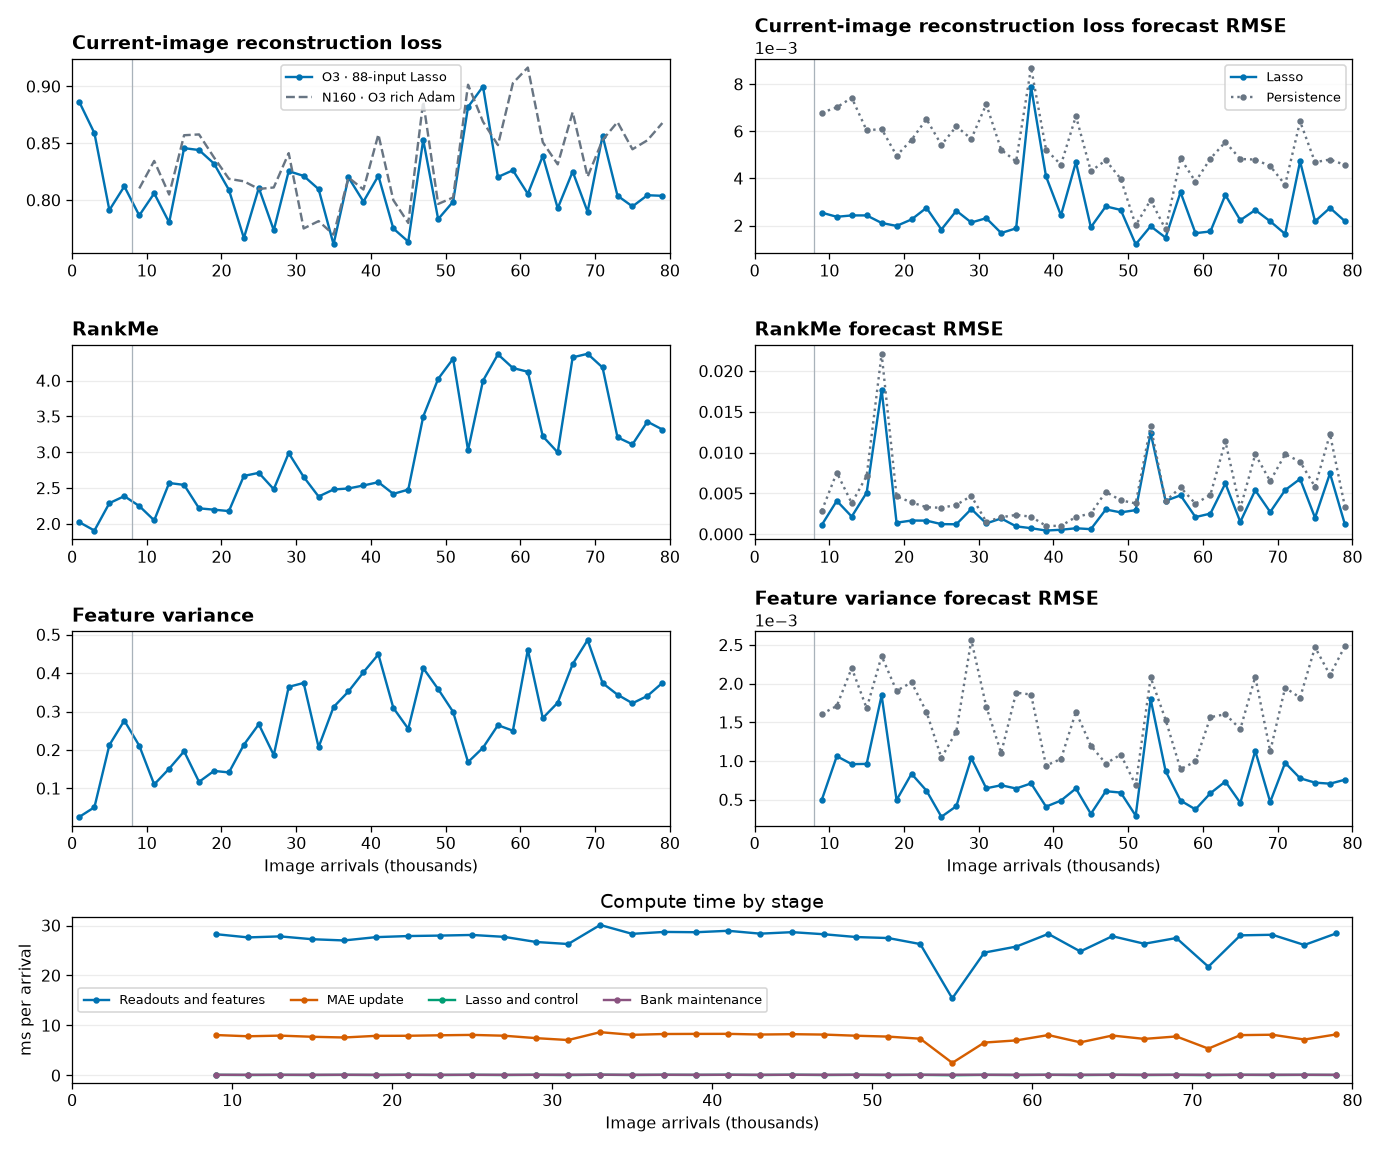

## Pooled RMSE on 66,492 executed updates

| Metric | Lasso | Persistence |
| --- | --- | --- |
 | Current-image reconstruction loss | 0.00289158 | 0.0054655 | 
 | RankMe | 0.00474462 | 0.00680424 | 
 | Feature variance | 0.000790947 | 0.0016946 | 

## Measured compute

| Stage | Total seconds | Mean ms per arrival |
| --- | --- | --- |
 | Pre-action readout and features | 1567.56 | 21.772 | 
 | Forecast and action choice | 2.65 | 0.037 | 
 | MAE update | 548.54 | 7.619 | 
 | Post-action readout | 382.35 | 5.310 | 
 | Lasso feedback | 4.02 | 0.056 | 
 | Bank maintenance | 10.38 | 0.144 | 
 | Lasso refit | 1.45 | 0.020 | 

## Protocol

Seed 2026 starts from the original 8,000-arrival calibration checkpoint used in N160. O3 chooses among Skip, 0.25× and 1× by minimizing predicted current-image loss change minus 0.25 times predicted RankMe change, after scaling both by their calibration state standard deviations. RankMe scaling is recomputed on the 96-arrival bank.

The 128-frame health bank follows notebook 172’s membership schedule. RankMe and raw variance use identical bank members before and after each action. The scheduled replacement occurs after scoring. Current-image reconstruction uses the original matched masks. N160 supplies the reconstruction-loss reference. Its health readouts used a different bank.

Lasso uses the same 88 inputs and proximal step as notebook 172. It refits every 4,000 arrivals using up to 16,000 measured past arrivals. An action absent from a refit window uses its calibration examples for that fit. The executed non-skip action supplies feedback only after its forecast is recorded. Each RMSE point scores executed updates in one 2,000-arrival window. Persistence predicts zero change.

In [ ]:
# Run this cell to refresh progress while the notebook is open.
from IPython.display import clear_output, display, Image, Markdown
from pathlib import Path
import json, time

folder = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-online-lasso-bank96')
while True:
    try:
        status = json.loads((folder / 'status.json').read_text(encoding='utf-8'))
        chart = (folder / 'curves.png').read_bytes()
    except (FileNotFoundError, PermissionError, ValueError):
        time.sleep(2)
        continue
    seconds = status['eta_seconds']
    eta = f'{seconds / 60:.1f} min' if seconds is not None else 'estimating'
    clear_output(wait=True)
    display(Markdown(f"**{status['state']}** · {status['cursor']:,}/{status['end']:,} arrivals · ETA {eta} · "
                     f"{status['scored']:,} updates scored · actions {status['actions']}"))
    display(Image(data=chart))
    if status['state'] in ('complete', 'failed', 'stopped'):
        if status['error']:
            display(Markdown(status['error']))
        break
    time.sleep(10)
